# BÁO CÁO LAB 02: DỰ ĐOÁN DOANH THU BÁN LẺ (RETAIL SALES FORECASTING)

## Step 0 — Định nghĩa Bài toán & Chiến lược Đánh giá
* **Bối cảnh Dữ liệu (Nguồn: Kaggle):** Bộ dữ liệu giao dịch xuyên quốc gia của một công ty trực tuyến chuyên bán lẻ và bán buôn các sản phẩm quà tặng có trụ sở tại Vương quốc Anh. Dữ liệu ghi nhận toàn bộ lịch sử mua hàng thực tế từ ngày 01/12/2010 đến 09/12/2011.
link: https://www.kaggle.com/datasets/ulrikthygepedersen/online-retail-dataset
* **Mục tiêu Nghiên cứu:** Không chỉ dừng lại ở một mô hình dự đoán đơn lẻ, dự án hướng tới việc xây dựng một **Hệ sinh thái AI Bán lẻ toàn diện** bao gồm 3 phân hệ: 
  1. Dự báo doanh thu đơn hàng (Regression).
  2. Dự báo xu hướng doanh thu tổng hệ thống trong 7 ngày tới (Time-Series Autoregression).
  3. Hệ thống gợi ý sản phẩm cá nhân hóa (Collaborative Filtering Recommender).
* **Quy tắc Lõi (Cốt lõi Kỹ thuật):** 100% các thuật toán máy học phức tạp (Linear Regression, Decision Tree, Random Forest, XGBoost) đều được nhóm **Code from scratch**.
*   **Chiến lược Chống rò rỉ dữ liệu (No Data Leakage):** Thay vì cung cấp sẵn số lượng mua (như kiểu giải toán nhân), nhóm ép mô hình phải thực sự dự đoán dựa trên thời điểm mua và thói quen tiêu tiền của từng quốc gia. Quan trọng nhất, mọi tính toán tổng hợp dữ liệu đều **chỉ thực hiện sau khi đã giấu kín tập Test**, đảm bảo mô hình không được "nhìn lén" đáp án.

## Step 1 — Nạp Dữ liệu
Dữ liệu được nạp từ thư mục `data/raw/online_retail.csv`. 

In [1]:
import os
import sys
import pandas as pd
from IPython.display import Image, display

PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))
if PROJECT_ROOT not in sys.path:
    sys.path.append(PROJECT_ROOT)

# Import các hàm từ file src/eda.py
from src.eda import (
    load_data, 
    basic_clean_for_eda, 
    print_outlier_analysis,
    plot_outlier_boxplots,
    plot_correlation_heatmap, 
    plot_top_selling_products, 
    plot_timeseries_rolling_mean, 
    ensure_dir
)

# Thiết lập các đường dẫn chuẩn xác
RAW_DATA_PATH = os.path.join(PROJECT_ROOT, 'data', 'raw', 'online_retail.csv')
OUTPUT_IMAGE_DIR = ensure_dir(os.path.join(PROJECT_ROOT, 'docs', 'images'))

print("Đã nạp toàn bộ cấu hình, hàm và đường dẫn thành công!")

Đã nạp toàn bộ cấu hình, hàm và đường dẫn thành công!


## Step 2 — Khám phá Dữ liệu Tổng quan (EDA Overview)
Quá trình này bao gồm các tác vụ:
1. **Làm sạch sơ bộ (Basic Cleaning):** Lọc bỏ các dữ liệu rác/lỗi (đơn hàng bị hủy có Số lượng $\le 0$, hoặc Đơn giá $\le 0$) và loại bỏ các dòng thiếu thông tin khách hàng.
2. **Nhận diện Giá trị Ngoại lai (Outlier Detection):** Sử dụng bảng thống kê mô tả và phép đo Bách phân vị (99th Percentile) kết hợp với Biểu đồ Hộp (Boxplot) để phát hiện các đơn hàng sỉ khổng lồ. Đây là cơ sở quan trọng để quyết định áp dụng phép biến đổi Logarit ở Step 3.
3. **Phân tích Hành vi & Tương quan (Behavior & Correlation):** Trực quan hóa Top 10 sản phẩm mang lại số lượng bán ra cao nhất và đánh giá Ma trận tương quan (Heatmap) giữa các biến số học (Quantity, UnitPrice, Sales).
4. **Phân tích Chuỗi thời gian (Time-Series Trends):** Biểu diễn xu hướng doanh thu theo thời gian thực tế, kết hợp với việc tính toán Đường trung bình trượt (Rolling Means) chu kỳ 7 ngày và 30 ngày để quan sát rõ hơn xu hướng mua sắm theo tuần và theo tháng.

*(Tất cả biểu đồ phân tích đều được hệ thống tự động xuất và lưu trữ tại thư mục `docs/images/` để phục vụ công tác báo cáo).*.

In [2]:
# Gọi hàm tải và làm sạch dữ liệu
df_raw = load_data(RAW_DATA_PATH)
df_clean = basic_clean_for_eda(df_raw)

# Xem trước 5 dòng dữ liệu sau khi làm sạch
display(df_clean.head())

Đang tải dữ liệu từ: d:\ML-02\data\raw\online_retail.csv
Đang làm sạch dữ liệu sơ bộ...


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Sales,YearMonth
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12



========== PHÂN TÍCH OUTLIER (GIÁ TRỊ NGOẠI LAI) ===========

1. BẢNG THỐNG KÊ MÔ TẢ (describe):
       Quantity  UnitPrice     Sales
count 530104.00  530104.00 530104.00
mean      10.54       3.91     20.12
std      155.52      35.92    270.36
min        1.00       0.00      0.00
25%        1.00       1.25      3.75
50%        3.00       2.08      9.90
75%       10.00       4.13     17.70
max    80995.00   13541.33 168469.60

2. ĐO LƯỜNG GIỚI HẠN BẰNG BÁCH PHÂN VỊ (99%):
  - 99% đơn hàng có Số lượng (Quantity) từ 100.00 trở xuống.
  - 99% đơn hàng có Doanh thu (Sales) từ $183.60 trở xuống.

  -> Có 4849 đơn hàng vượt ngưỡng 99% Số lượng (Cần cẩn thận!)
  -> Có 5279 đơn hàng vượt ngưỡng 99% Doanh thu (Cần cẩn thận!)

Đang vẽ Biểu đồ Hộp (Boxplots) để nhận diện Outlier...
Đang vẽ Ma trận tương quan (Correlation Heatmap)...
Đang vẽ biểu đồ Top 10 sản phẩm bán chạy nhất...


d:\ML-02\src\eda.py:81: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_products.values, y=top_products.index, palette='viridis')


Đang vẽ phân tích chuỗi thời gian (Rolling Means)...
--------------------------------------------------
1. MA TRẬN TƯƠNG QUAN CÁC BIẾN SỐ HỌC


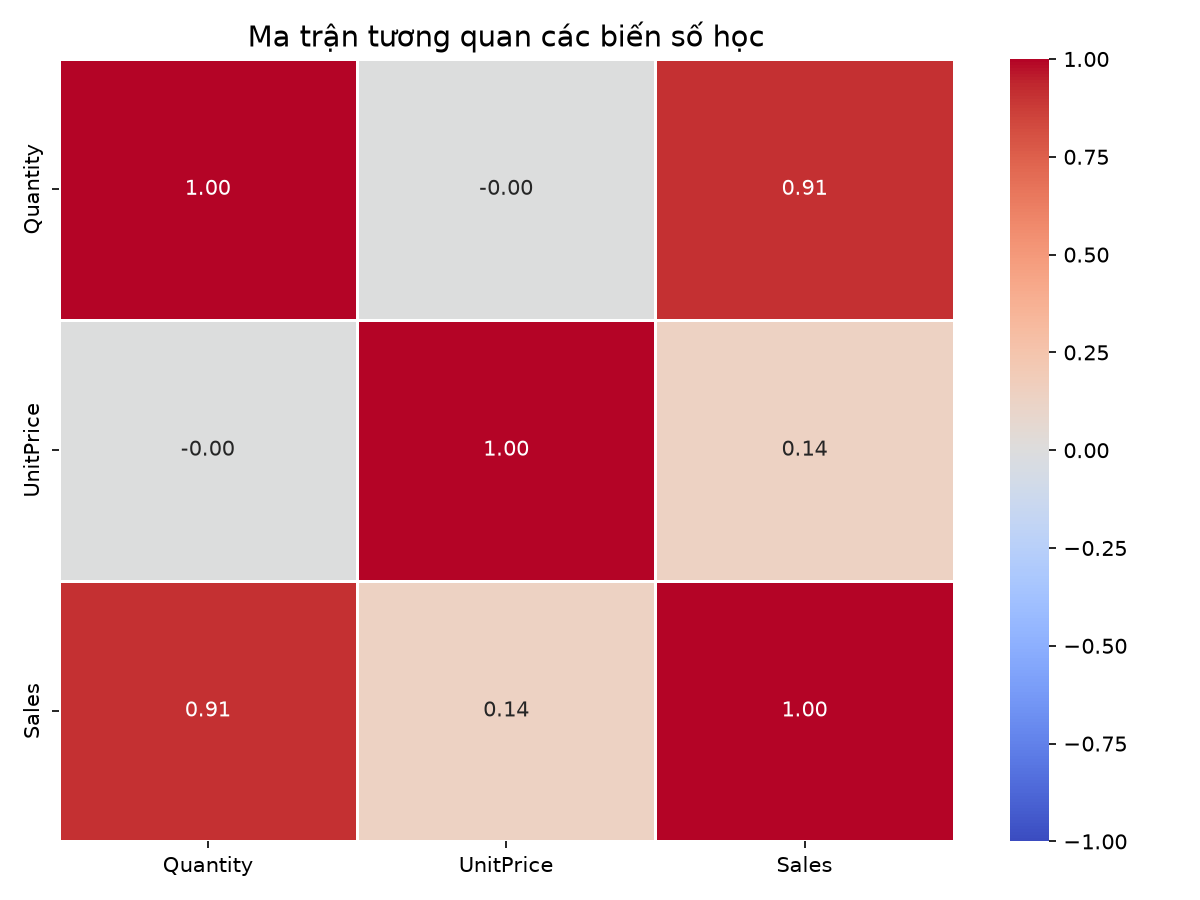


--------------------------------------------------
2. TOP 10 SẢN PHẨM BÁN CHẠY NHẤT


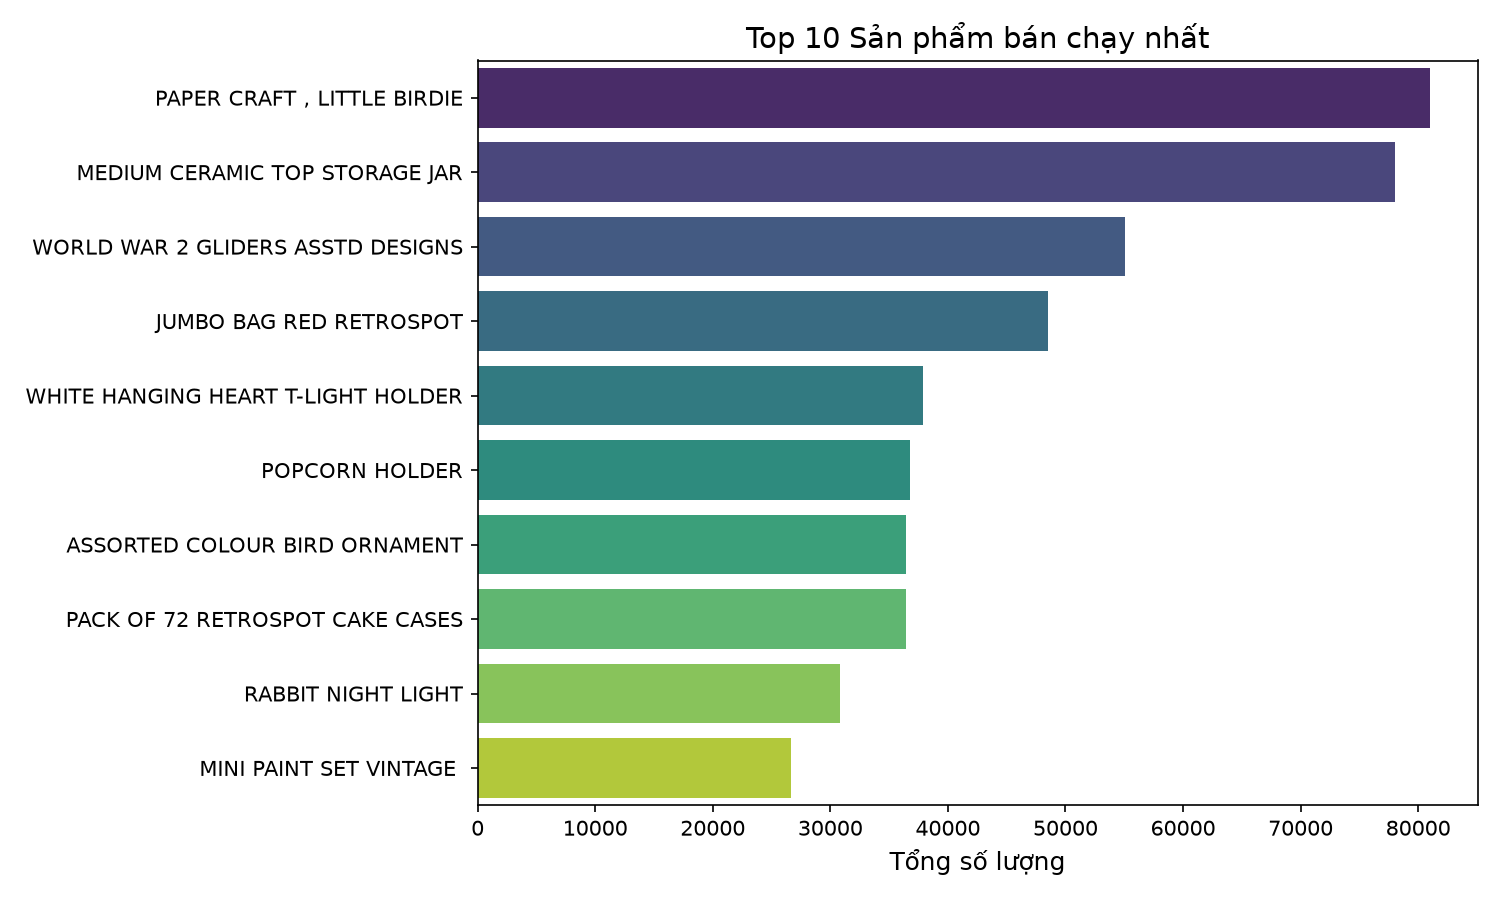


--------------------------------------------------
3. PHÂN TÍCH XU HƯỚNG THỜI GIAN (ROLLING MEANS)


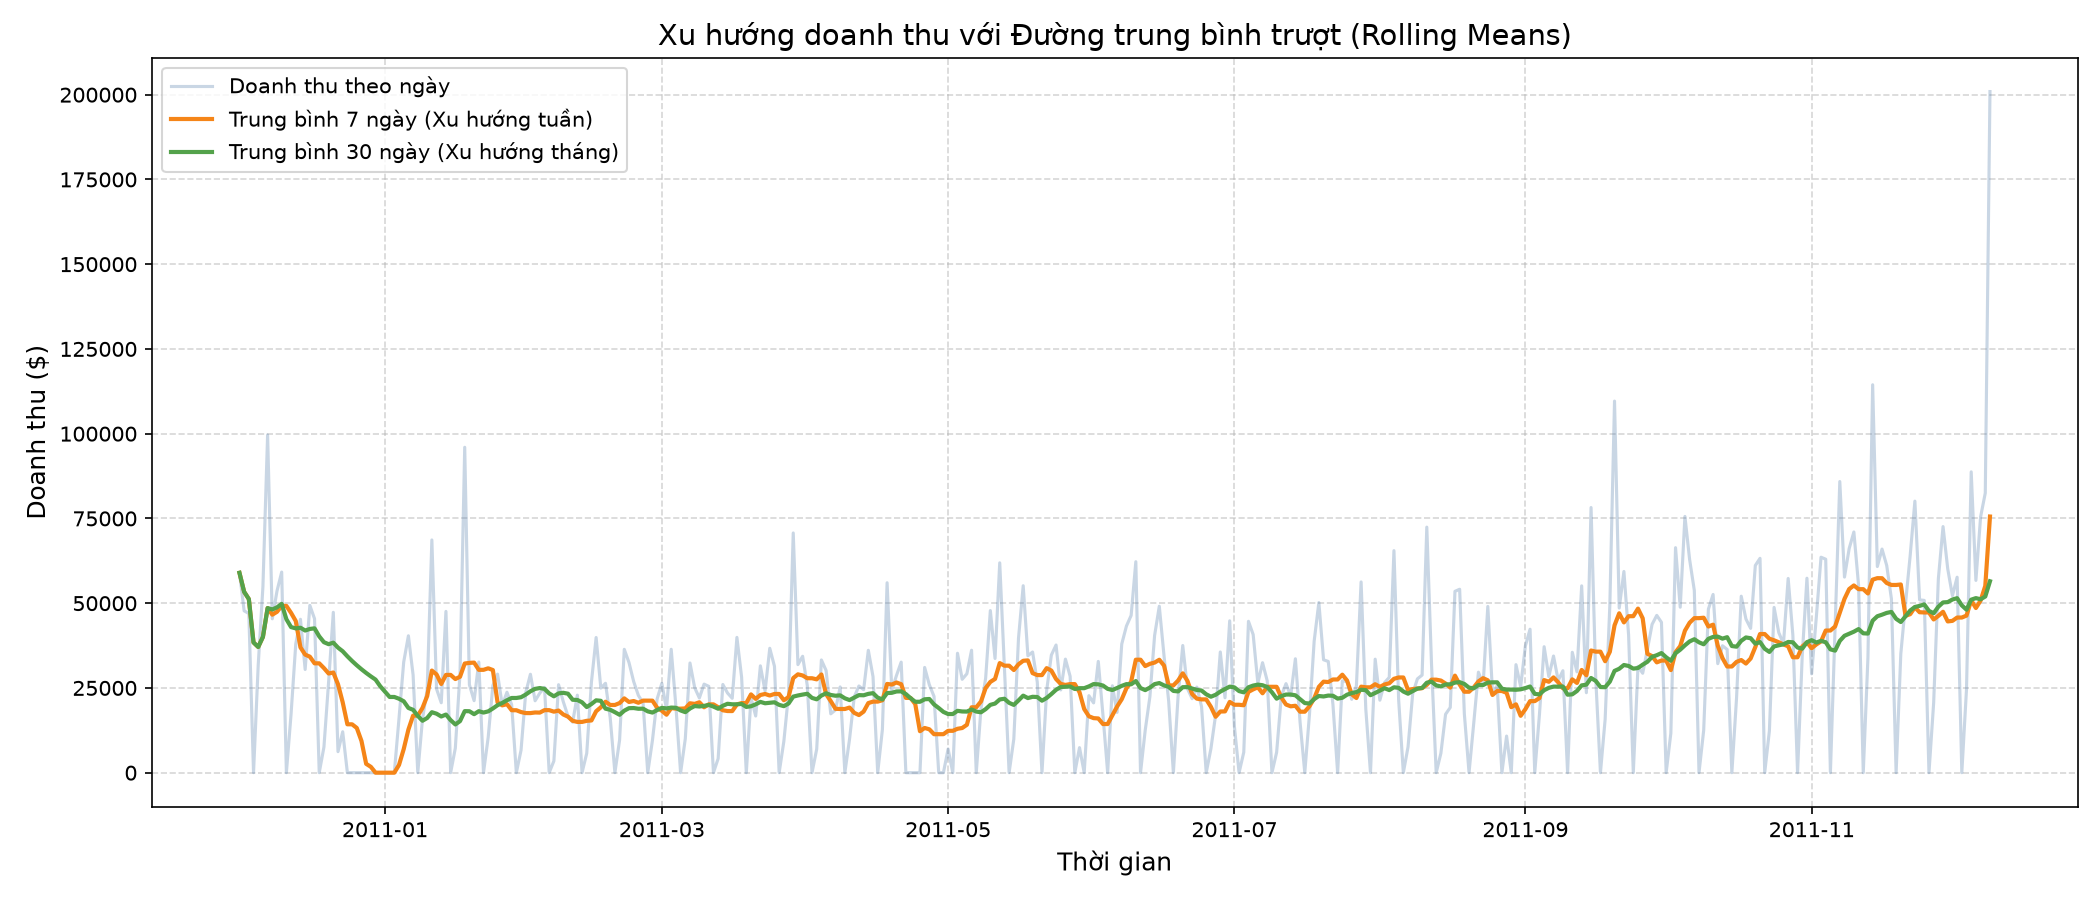


--------------------------------------------------
4. PHÂN TÍCH ĐIỂM NGOẠI LAI (BOXPLOTS)


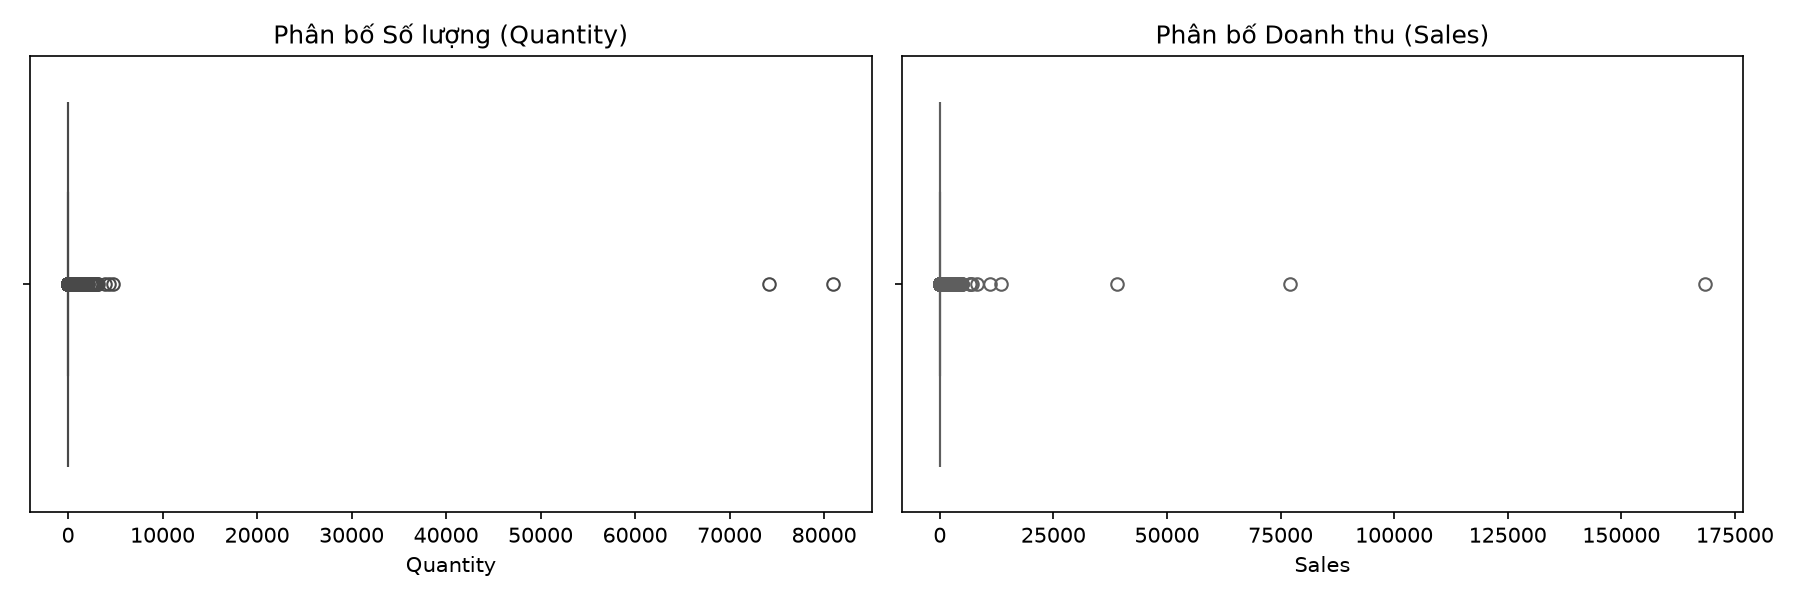

In [3]:
# 1. Chạy các hàm từ src/eda.py
print_outlier_analysis(df_clean)
plot_outlier_boxplots(df_clean, OUTPUT_IMAGE_DIR)

plot_correlation_heatmap(df_clean, OUTPUT_IMAGE_DIR)
plot_top_selling_products(df_clean, OUTPUT_IMAGE_DIR)
plot_timeseries_rolling_mean(df_clean, OUTPUT_IMAGE_DIR)

# 2. Hiển thị các ảnh đã lưu trực tiếp trên Notebook
print("-" * 50)
print("1. MA TRẬN TƯƠNG QUAN CÁC BIẾN SỐ HỌC")
display(Image(filename=os.path.join(OUTPUT_IMAGE_DIR, 'correlation_heatmap.png')))

print("\n" + "-" * 50)
print("2. TOP 10 SẢN PHẨM BÁN CHẠY NHẤT")
display(Image(filename=os.path.join(OUTPUT_IMAGE_DIR, 'top_products.png')))

print("\n" + "-" * 50)
print("3. PHÂN TÍCH XU HƯỚNG THỜI GIAN (ROLLING MEANS)")
display(Image(filename=os.path.join(OUTPUT_IMAGE_DIR, 'timeseries_trends.png')))

print("\n" + "-" * 50)
print("4. PHÂN TÍCH ĐIỂM NGOẠI LAI (BOXPLOTS)")
display(Image(filename=os.path.join(OUTPUT_IMAGE_DIR, 'outlier_boxplots.png')))

## Step 3 — Tiền xử lý & Trích xuất đặc trưng (Feature Engineering)
Quá trình này biến đổi dữ liệu thô thành các vector đặc trưng số học và xử lý các giá trị dị biệt trước khi đưa vào mô hình học máy. Các bước thực hiện bao gồm:
1. **Trích xuất đặc trưng thời gian:** Phân tách `InvoiceDate` thành các cột vĩ mô (Tháng, Ngày, Thứ trong tuần).
2. **Ngăn chặn rò rỉ dữ liệu (No Data Leakage):** Tiến hành chia tách tập Train/Test theo tỷ lệ 80-20 **TRƯỚC** khi thực hiện bất kỳ phép tính toán tổng hợp hay mã hóa nào.
3. **Tạo đặc trưng lịch sử:** Tính toán sức mua trung bình (`Country_Historical_Avg_Sales`) dựa trên tập Train, sau đó ánh xạ (map) một chiều sang tập Test để đối phó với các khách hàng/thị trường mới.
4. **Lựa chọn đặc trưng (Feature Selection):** Loại bỏ hoàn toàn các biến định danh (`InvoiceNo`, `StockCode`) và đặc biệt là cấm sử dụng `Quantity`, `UnitPrice` trong tập $X$. Quyết định này ép mô hình từ bỏ việc "làm toán nhân" để chuyển sang thực sự "dự đoán" doanh thu dựa trên bối cảnh.
5. **Biến đổi Logarit (Log Transformation):** Áp dụng hàm logarit tự nhiên `np.log1p()` lên biến mục tiêu $y$ (`Sales`). Đây là kỹ thuật cốt lõi giúp chuẩn hóa phân phối dữ liệu, triệt tiêu tác động tiêu cực của các đơn hàng sỉ khổng lồ (Outliers) lên hàm mất mát (Loss function) trong quá trình huấn luyện.

In [4]:
# Import hàm main từ file src/preprocess.py để chạy toàn bộ luồng
from src.preprocess import main as run_preprocessing

print("BẮT ĐẦU QUÁ TRÌNH TIỀN XỬ LÝ VÀ CHIA TẬP DỮ LIỆU...")
run_preprocessing()

BẮT ĐẦU QUÁ TRÌNH TIỀN XỬ LÝ VÀ CHIA TẬP DỮ LIỆU...
Đang làm sạch dữ liệu: Xử lý missing values và hóa đơn lỗi...
Đang trích xuất đặc trưng thời gian...
Đang chia tách Train/Test (80-20)...
    -> [OK] Kiểm tra rò rỉ: Dữ liệu an toàn.
[*] Đang lưu các ma trận và từ điển mappings vào d:\ML-02\data\processed...

 ĐÃ HOÀN TẤT TIỀN XỬ LÝ NÂNG CAO!
    - Kích thước tập X_train: (318308, 5)
    - Kích thước tập X_test:  (79576, 5)


### Kiểm tra tập dữ liệu sau xử lý
hệ thống đã lưu 4 ma trận dữ liệu (`X_train.pkl`, `X_test.pkl`, `y_train.pkl`, `y_test.pkl`) vào thư mục `data/processed/`. Chúng ta sẽ tải lên để kiểm tra cấu trúc của `X_train`.

In [5]:
# Xác định đường dẫn thư mục processed
PROCESSED_DIR = os.path.join(PROJECT_ROOT, 'data', 'processed')

# Đọc thử file X_train và y_train để chứng minh dữ liệu đã sẵn sàng
X_train = pd.read_pickle(os.path.join(PROCESSED_DIR, 'X_train.pkl'))
y_train = pd.read_pickle(os.path.join(PROCESSED_DIR, 'y_train.pkl'))

print("\n--- Kích thước tập huấn luyện ---")
print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")

print("\n--- 5 DÒNG ĐẦU TIÊN CỦA TẬP ĐẶC TRƯNG (X_TRAIN) ---")
display(X_train.head())


--- Kích thước tập huấn luyện ---
X_train shape: (318308, 5)
y_train shape: (318308,)

--- 5 DÒNG ĐẦU TIÊN CỦA TẬP ĐẶC TRƯNG (X_TRAIN) ---


,Month,Day,DayOfWeek,Country_Encoded,Country_Historical_Avg_Sales
429013,10,31,0,0,20.787336
157177,4,15,4,0,20.787336
29804,12,14,1,1,22.333340
505646,11,28,0,0,20.787336
327798,9,6,1,0,20.787336


## Step 4: Huấn luyện Mô hình (Model Training from Scratch)
Trong bước này, chúng ta tiến hành huấn luyện dữ liệu trên 4 thuật toán Hồi quy (Regression). Điểm đặc biệt của dự án này là **toàn bộ 4 thuật toán đều được lập trình hoàn toàn bằng Toán học và Numpy từ con số 0 (from scratch)**, không sử dụng các thư viện có sẵn như `scikit-learn` cho phần lõi:

1. **Linear Regression:** Áp dụng phương pháp *Normal Equation* (Phương trình chuẩn) tính toán ma trận giả nghịch đảo (pseudo-inverse) để tìm ra bộ trọng số tối ưu nhất chỉ trong một bước.
2. **Decision Tree Regressor:** Thuật toán xây dựng cây quyết định dựa trên kỹ thuật tính toán *Giảm phương sai (Variance Reduction)* để tìm ra đặc trưng và điểm cắt (threshold) tốt nhất tại mỗi nút.
3. **Random Forest Regressor:** Thuật toán học tập hợp (Ensemble). Sử dụng kỹ thuật *Bootstrapping* để tạo ra nhiều tập dữ liệu con, huấn luyện nhiều cây Decision Tree độc lập và lấy trung bình cộng để chống Overfitting.
4. **XGBoost Regressor:** Thuật toán học tăng cường (Boosting). Huấn luyện các cây quyết định tuần tự, trong đó cây sau sẽ cố gắng dự đoán và bù đắp lại phần sai số (Residuals) của tập hợp các cây trước đó.

In [6]:
import src.train
src.train.main()

 Đang đọc cấu hình siêu tham số từ config.yaml...
 Đang tải X_train và y_train từ d:\ML-02\data/processed...

        BẮT ĐẦU HUẤN LUYỆN 4 MÔ HÌNH (FROM SCRATCH)         
  [1/4] Đang huấn luyện Linear Regression... XONG! (Mất 0.10s) -> Đã lưu linear_regression.pkl
  [2/4] Đang huấn luyện Decision Tree... XONG! (Mất 0.58s) -> Đã lưu decision_tree.pkl
  [3/4] Đang huấn luyện Random Forest... [*] Đang huấn luyện Random Forest bằng Joblib...
XONG! (Mất 32.06s) -> Đã lưu random_forest.pkl
  [4/4] Đang huấn luyện XGBoost... XONG! (Mất 46.14s) -> Đã lưu xgboost.pkl
------------------------------------------------------------
 Đang ghi log thử nghiệm vào d:\ML-02\docs/experiment_logs.csv...

 ĐÃ HOÀN TẤT HUẤN LUYỆN!
    - Tổng thời gian huấn luyện: 78.87 giây
    - Toàn bộ mô hình nằm tại: d:\ML-02\models


### Trực quan hóa Lịch sử Thử nghiệm (Experiment Tracking)
Để theo dõi quá trình tinh chỉnh siêu tham số (Hyperparameter Tuning), mỗi lần chạy huấn luyện hệ thống đều tự động ghi log cấu hình tham số và thời gian chạy vào file `docs/experiment_logs.csv`. 

Dưới đây là bảng lịch sử các lần chạy gần nhất:

In [7]:
import pandas as pd
from IPython.display import display

# Đường dẫn tới file log
log_path = os.path.join(PROJECT_ROOT, 'docs', 'experiment_logs.csv')

if os.path.exists(log_path):
    df_logs = pd.read_csv(log_path)
    print(f"Tổng số lần đã chạy thử nghiệm: {len(df_logs)} lần")
    print("\n--- CHI TIẾT 5 LẦN THỬ NGHIỆM GẦN NHẤT ---")
    
    # Dùng style của pandas để bảng hiện ra trên Notebook đẹp hơn
    display(df_logs.tail(5).style.set_properties(**{
        'background-color': '#f4f4f4',
        'color': 'black',
        'border-color': 'white'
    }))
else:
    print("Chưa có file log nào được tạo. Hãy đảm bảo src.train.main() đã chạy thành công.")

Tổng số lần đã chạy thử nghiệm: 5 lần

--- CHI TIẾT 5 LẦN THỬ NGHIỆM GẦN NHẤT ---


,Timestamp,LR_Params,DT_Params,RF_Params,XGB_Params,Total_Train_Time_Sec
0,2026-10-19 00:38:13,"{'learning_rate': 0.01, 'n_iterations': 1000}","{'max_depth': 15, 'min_samples_split': 40}","{'n_trees': 100, 'max_depth': 15, 'min_samples_split': 40}","{'n_estimators': 100, 'learning_rate': 0.05, 'max_depth': 5, 'min_samples_split': 20}",137.470000
1,2026-10-19 01:16:14,"{'learning_rate': 0.01, 'n_iterations': 1000}","{'max_depth': 15, 'min_samples_split': 40}","{'n_trees': 100, 'max_depth': 15, 'min_samples_split': 40}","{'n_estimators': 100, 'learning_rate': 0.05, 'max_depth': 5, 'min_samples_split': 20}",149.600000
2,2026-10-19 01:32:08,"{'learning_rate': 0.01, 'n_iterations': 1000}","{'max_depth': 15, 'min_samples_split': 40}","{'n_trees': 100, 'max_depth': 15, 'min_samples_split': 40}","{'n_estimators': 100, 'learning_rate': 0.05, 'max_depth': 5, 'min_samples_split': 20}",151.280000
3,2026-10-19 01:51:17,"{'learning_rate': 0.01, 'n_iterations': 1000}","{'max_depth': 15, 'min_samples_split': 40}","{'n_trees': 100, 'max_depth': 15, 'min_samples_split': 40}","{'n_estimators': 100, 'learning_rate': 0.05, 'max_depth': 5, 'min_samples_split': 20}",151.450000
4,2026-10-19 10:15:36,"{'learning_rate': 0.01, 'n_iterations': 1000}","{'max_depth': 15, 'min_samples_split': 40}","{'n_trees': 100, 'max_depth': 15, 'min_samples_split': 40}","{'n_estimators': 100, 'learning_rate': 0.05, 'max_depth': 3, 'min_samples_split': 30, 'subsample': 0.6, 'max_features': 'sqrt'}",78.870000


## Step 5: Đánh giá Mô hình (Model Evaluation)
Dựa trên kết quả chạy thử nghiệm được ghi nhận, chúng ta đã tiến hành đánh giá 4 mô hình học máy khác nhau bao gồm:
**Linear Regression, Decision Tree, XGBoost và Random Forest**.
Các mô hình này được đánh giá song song trên cả hai tập dữ liệu: **tập huấn luyện (Train) và tập kiểm thử (Test)** nhằm đo lường khả năng học hỏi cũng như khả năng tổng quát hóa (dự đoán trên dữ liệu mới chưa từng thấy).   

Các chỉ số đánh giá được tính toán hoàn toàn bằng các hàm tự code (trong `src/utils.py`) bao gồm:
- **MAE (Mean Absolute Error):** Sai số tuyệt đối trung bình.
- **MSE (Mean Squared Error) & RMSE (Root Mean Squared Error):** Sai số bình phương trung bình, giúp phạt nặng các dự đoán sai lệch lớn.
- **R-squared ($R^2$):** Hệ số xác định, thể hiện mô hình giải thích được bao nhiêu % sự biến thiên của dữ liệu (càng gần 1 càng tốt).

In [8]:
# Gọi hàm đánh giá từ file src/evaluate.py
import src.evaluate

print(" BẮT ĐẦU QUÁ TRÌNH ĐÁNH GIÁ TRÊN TẬP TRAIN VÀ TEST...")
src.evaluate.main()

 BẮT ĐẦU QUÁ TRÌNH ĐÁNH GIÁ TRÊN TẬP TRAIN VÀ TEST...
 Đang tải dữ liệu Train và Test từ d:\ML-02\data\processed...

 ĐANG ĐÁNH GIÁ CÁC MÔ HÌNH (TRAIN vs TEST)...
    -> Đang chạy dự đoán với Linear_Regression...
    -> Đang chạy dự đoán với Decision_Tree...
    -> Đang chạy dự đoán với Random_Forest...
    -> Đang chạy dự đoán với XGBoost...

================ BẢNG XẾP HẠNG HIỆU NĂNG CÁC MÔ HÌNH (TRAIN vs TEST) ================
| Mô hình           |   Train MAE |   Test MAE |   Train MSE |   Test MSE |   Train RMSE |   Test RMSE |   Train R2 |   Test R2 |
|:------------------|------------:|-----------:|------------:|-----------:|-------------:|------------:|-----------:|----------:|
| Decision_Tree     |     16.3281 |    15.7195 | 117760.0288 |  5813.9532 |     343.1618 |     76.2493 |     0.0015 |    0.0119 |
| Random_Forest     |     16.3103 |    15.6677 | 117825.6459 |  5819.1487 |     343.2574 |     76.2833 |     0.0009 |    0.0110 |
| XGBoost           |     16.7481 |    16.0189 |

##  Phân tích chi tiết từng mô hình
### Decision Tree 
Là mô hình đứng đầu với Test R2 cao nhất (0.0119). Dù được xếp hạng tốt nhất, mức R2 này gần như tiệm cận 0, chứng tỏ mô hình chỉ giải thích được khoảng 1% sự biến thiên của dữ liệu.
### Random Forest
Bám sát Decision Tree với Test R2 đạt 0.0110 và sở hữu sai số tuyệt đối thấp nhất (Test MAE = 15.6677). Tuy nhiên, kết quả này vẫn không đủ đáp ứng yêu cầu dự báo thực tế.
###  XGBoost
Cho kết quả Test R2 âm (-0.0031). Trong thống kê, R2 âm có nghĩa là hiệu năng của thuật toán này còn tệ hơn việc bạn lấy con số doanh thu trung bình để dự đoán cho mọi trường hợp.

### Linear Regression 
Kém nhất trong nhóm với Test R2 âm sâu nhất (-0.0050) và mức sai số Test MAE cao nhất (16.2302). Thuật toán tuyến tính hoàn toàn bất lực trong việc tìm ra quy luật từ tập dữ liệu này.


##  Kết luận 

Mặc dù hệ thống kết luận Decision Tree là mô hình tốt nhất với Test R2 = 0.0119, nhưng sự thật là cả 4 mô hình đều không thể sử dụng để dự báo thực tế. Việc các chỉ số R2 đều xoay quanh mức 0 hoặc âm khẳng định rằng nguyên nhân không nằm ở thuật toán (XGBoost hay Random Forest đều là những mô hình rất mạnh), mà là do dữ liệu đầu vào không chứa "tín hiệu" (signal) để mô hình học hỏi.

### Đề xuất hướng giải quyết

* **Thực hiện Feature Engineering mạnh tay hơn:** Tập đặc trưng hiện tại vô tác dụng. Cần bổ sung các biến có tính cá nhân hóa và lịch sử như: phân khúc khách hàng RFM (Recency, Frequency, Monetary), lịch sử mua hàng, hoặc đặc trưng độ trễ (Lagged features - ví dụ: doanh thu của mã hàng này trong 7 ngày trước).
* **Đổi góc độ bài toán (Aggregation):** Việc dự đoán doanh thu của từng dòng hóa đơn đơn lẻ chứa quá nhiều biến số ngẫu nhiên. Hãy thử tổng hợp (groupby) để dự báo tổng doanh thu theo ngày, tổng doanh thu theo tuần, hoặc tổng chi tiêu của một khách hàng trong tháng.
* **Làm sạch nhiễu (Noise):** Cần rà soát lại các điểm ngoại lai (Outliers). Một vài hóa đơn bán sỉ đột biến có thể đang bóp méo hoàn toàn hàm mất mát (loss function) của các mô hình Hồi quy.

### Phân tích Biểu đồ Chẩn đoán (Diagnostic Plots)
Để hiểu sâu hơn về chất lượng dự đoán, ta cần xem xét 2 biểu đồ:
1. **Thực tế vs Dự đoán (Actual vs Predicted):** Nếu các điểm dữ liệu bám sát đường chéo màu đỏ, chứng tỏ mô hình dự đoán rất sát với thực tế.
2. **Phân bố phần dư (Residuals Plot):** Nếu phần dư phân tán ngẫu nhiên quanh đường số 0 và không có hình thù phễu, chứng tỏ phương sai của mô hình là ổn định.

Dưới đây là biểu đồ của 4 thuật toán:


--- BIỂU ĐỒ CHẨN ĐOÁN: LINEAR REGRESSION ---


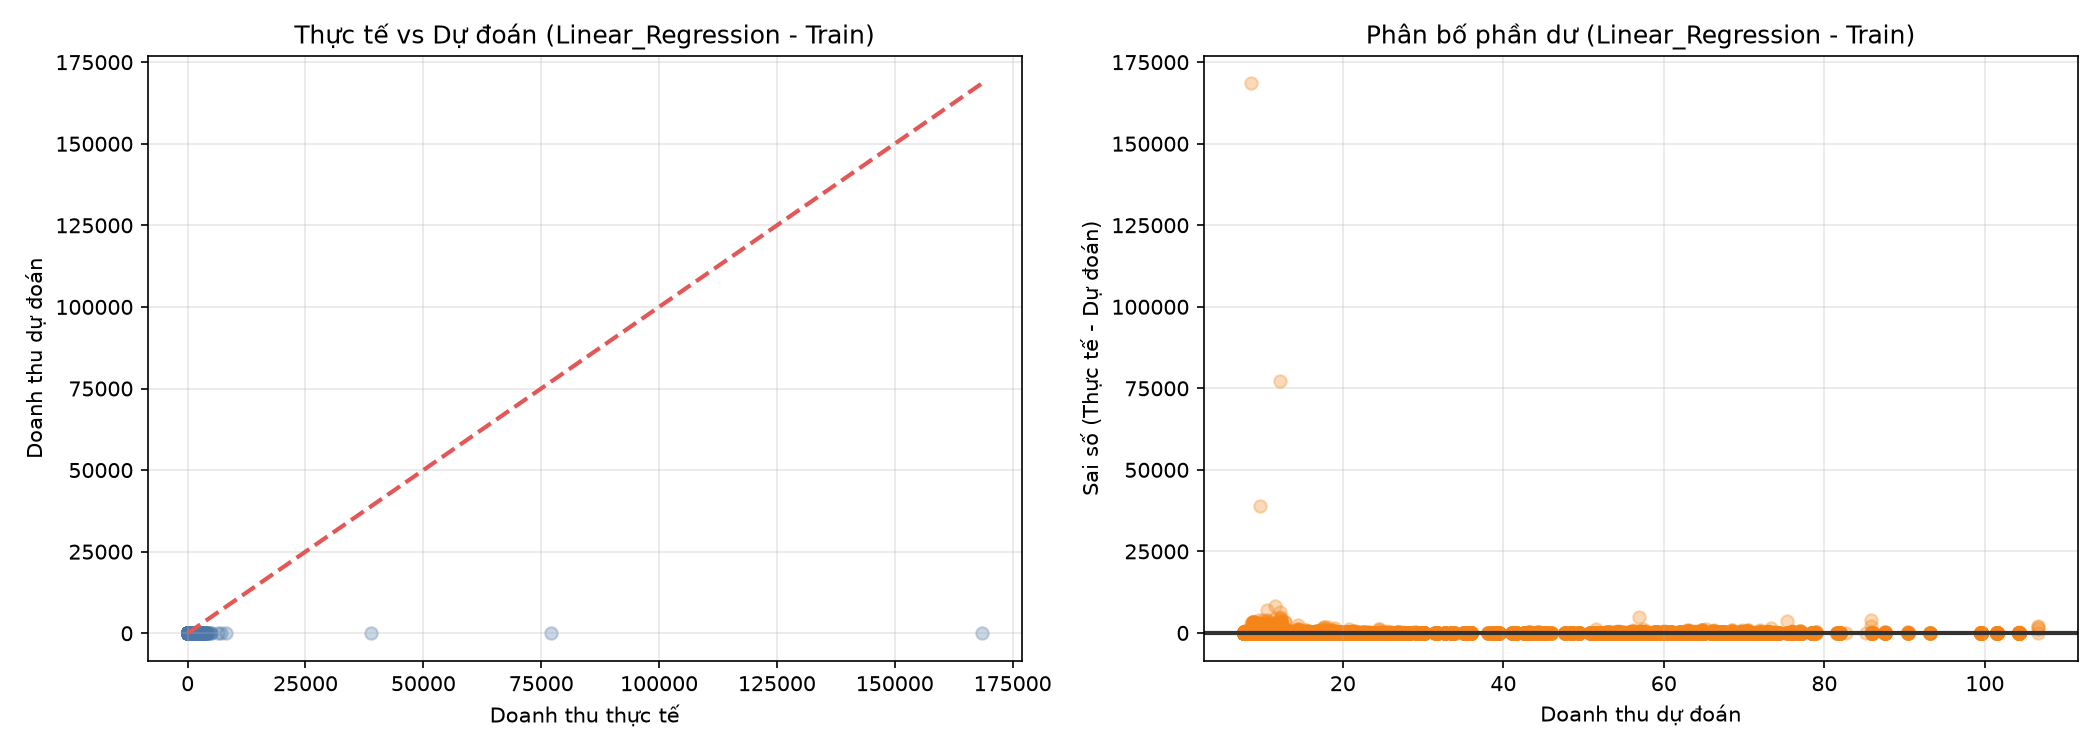

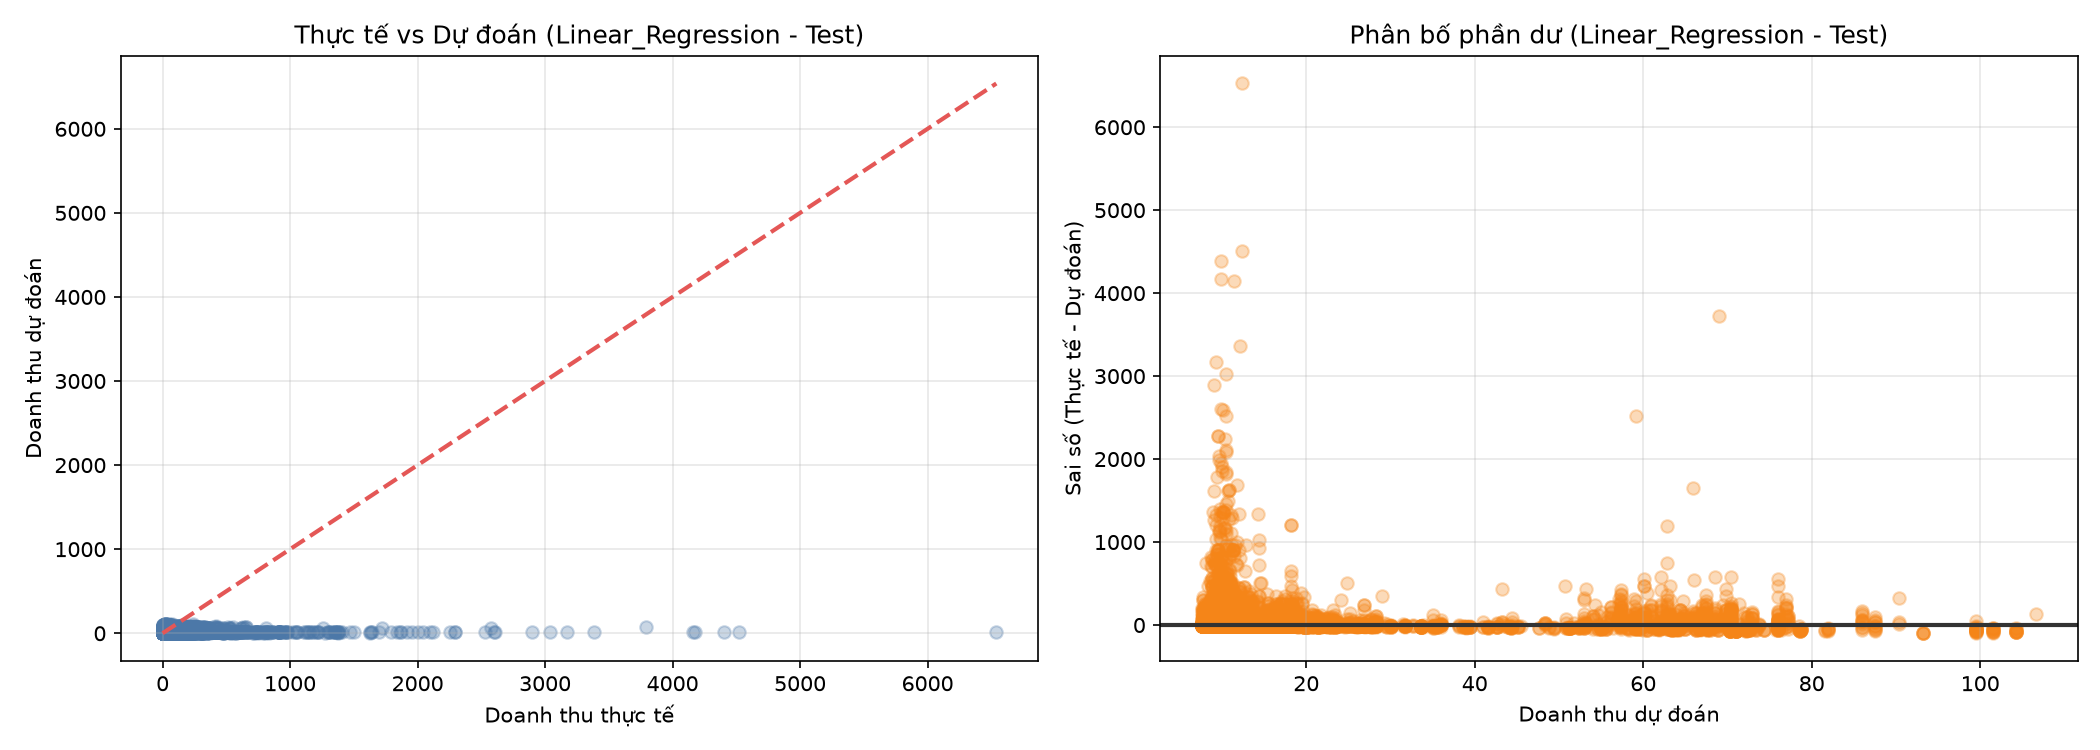


--- BIỂU ĐỒ CHẨN ĐOÁN: DECISION TREE ---


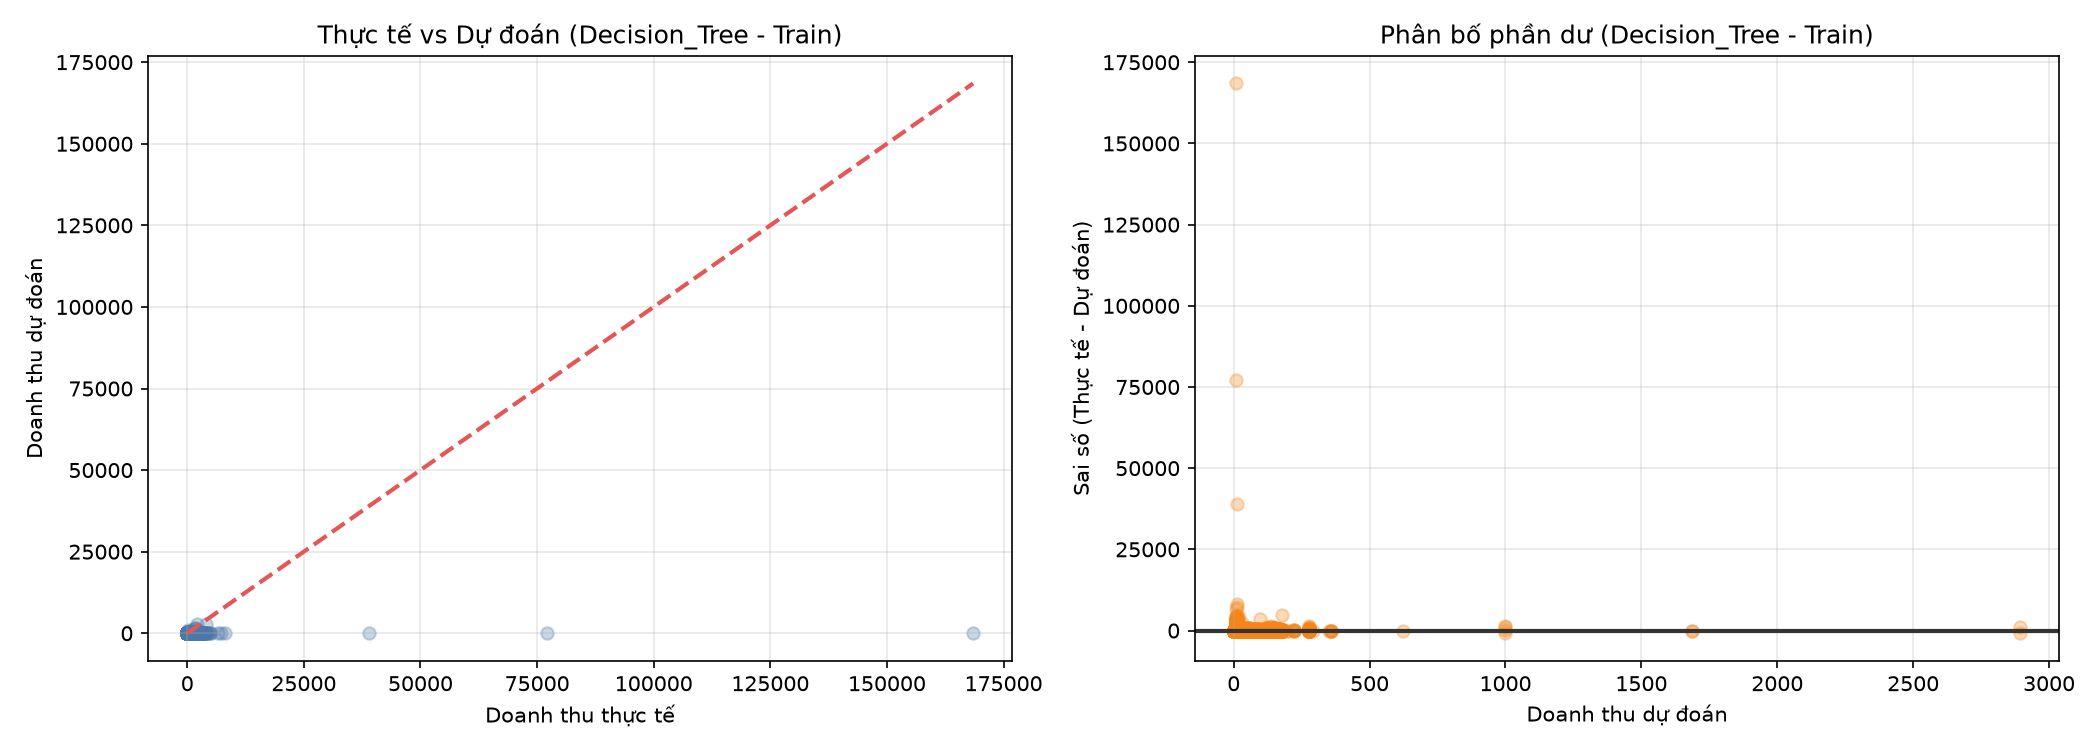

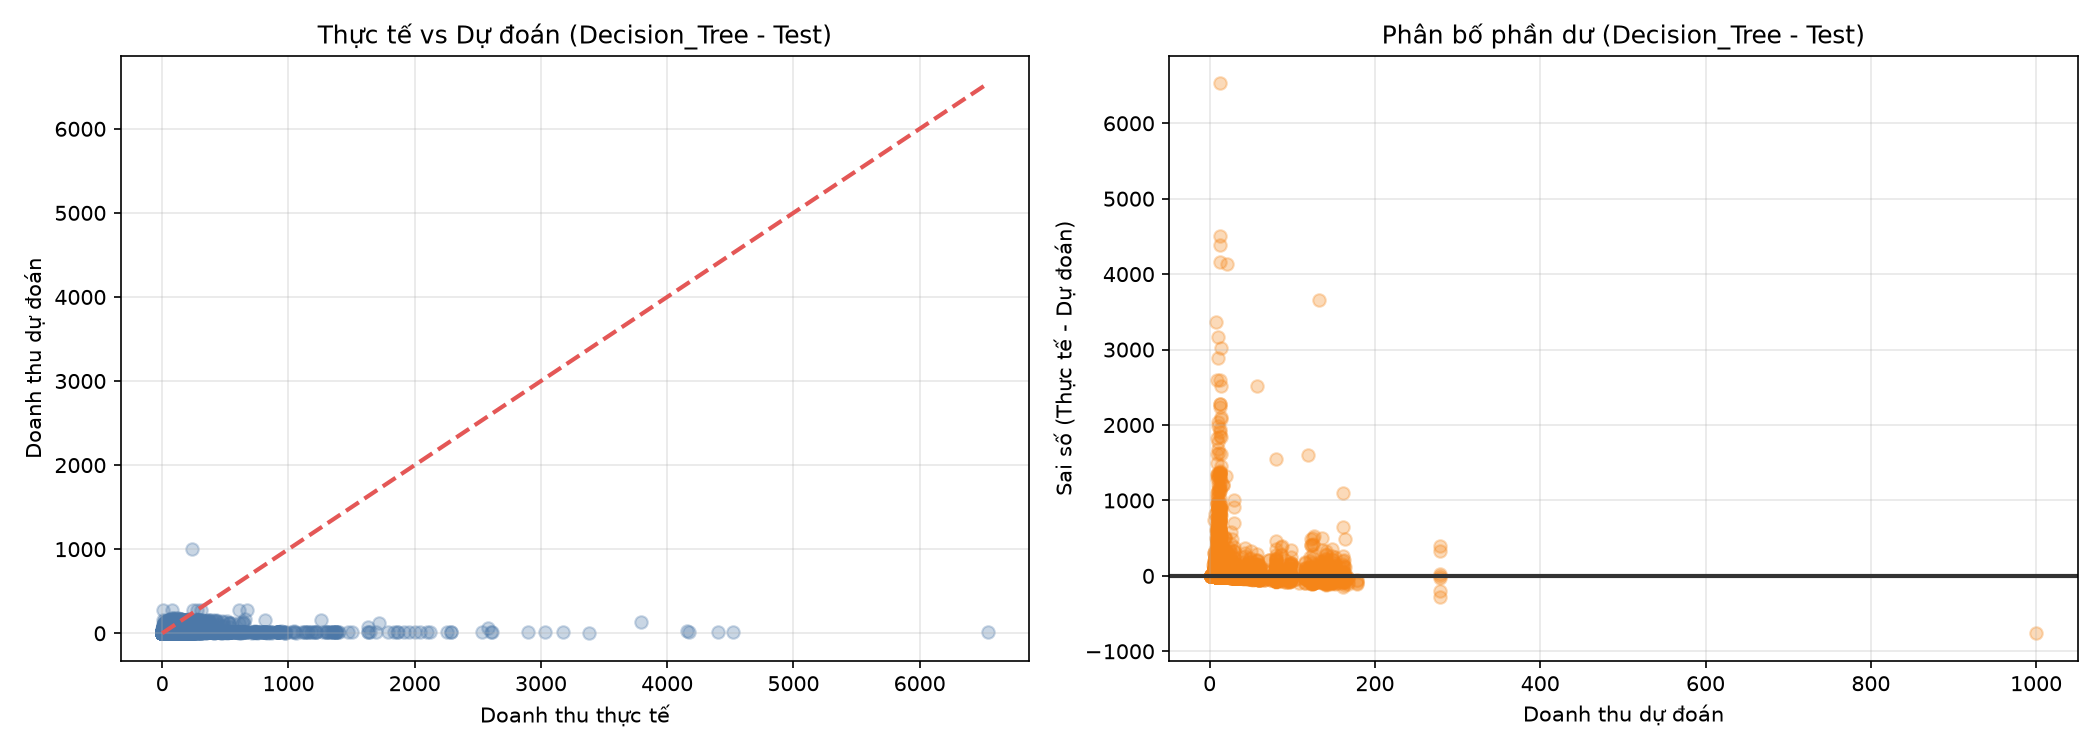


--- BIỂU ĐỒ CHẨN ĐOÁN: RANDOM FOREST ---


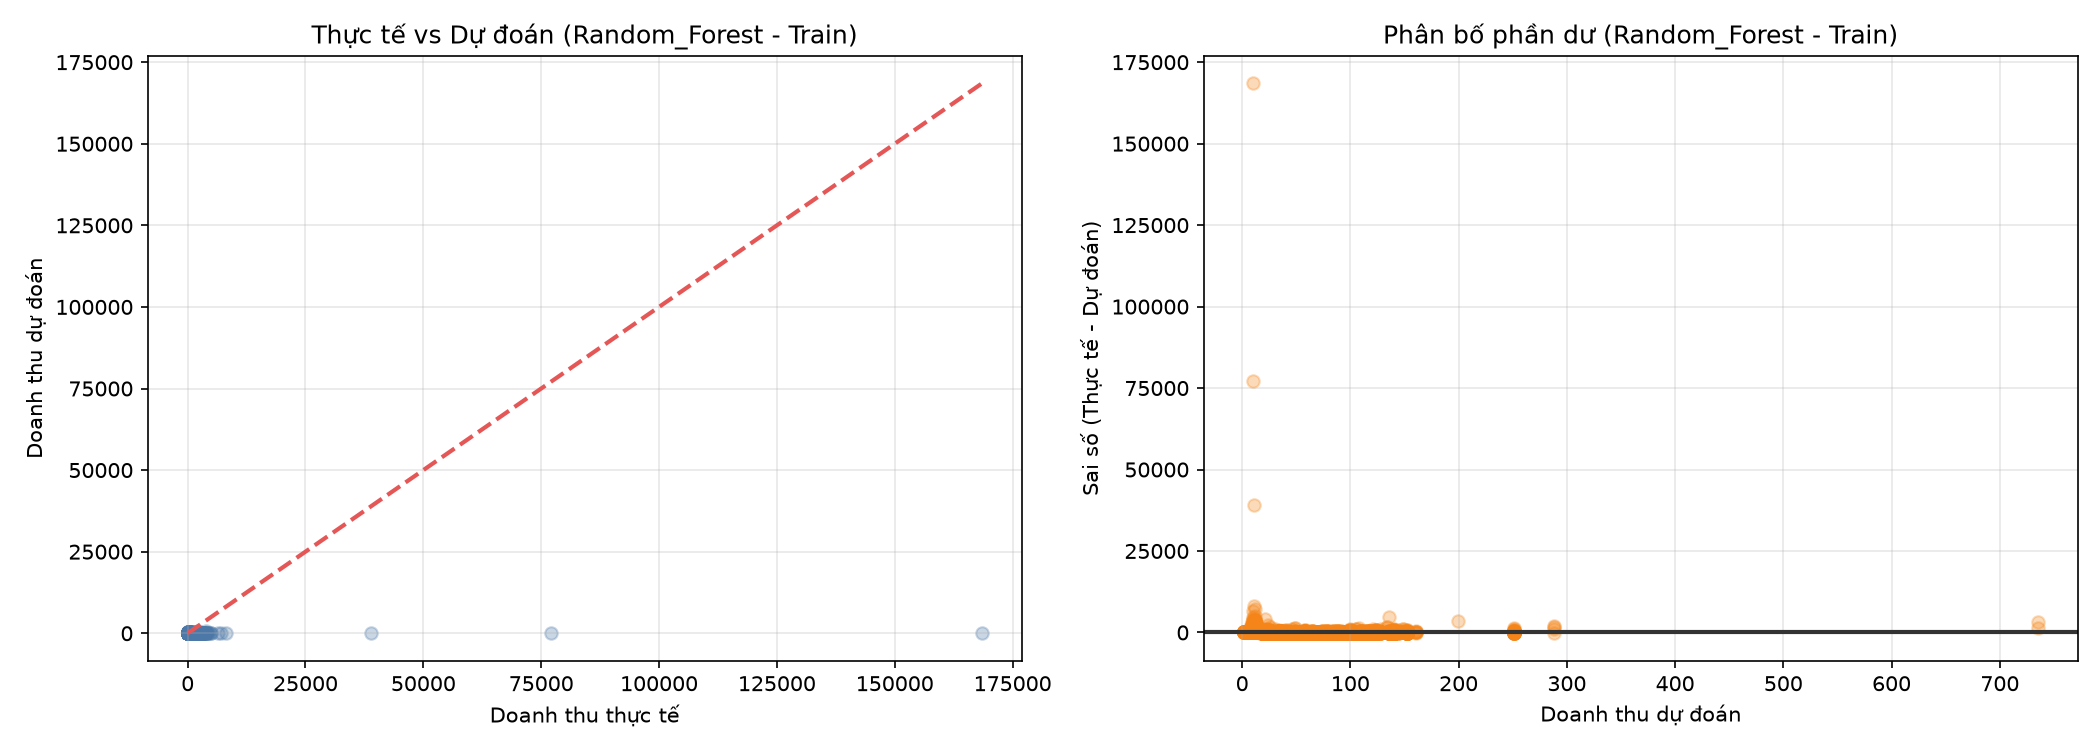

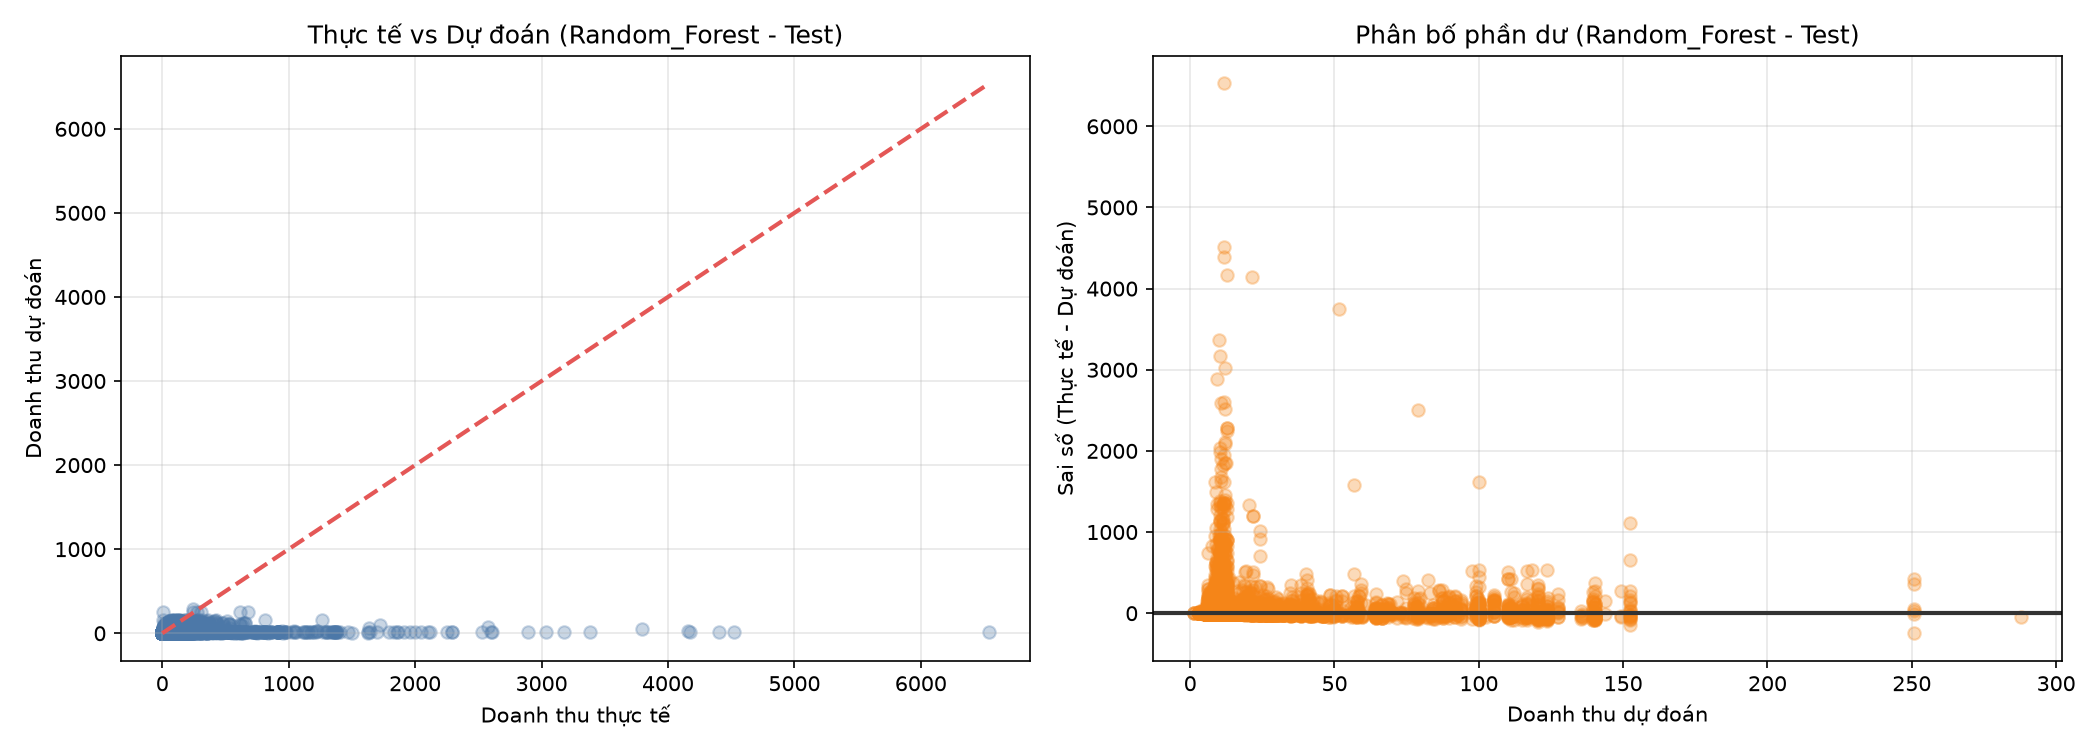

--- BIỂU ĐỒ CHẨN ĐOÁN: XGBOOST ---


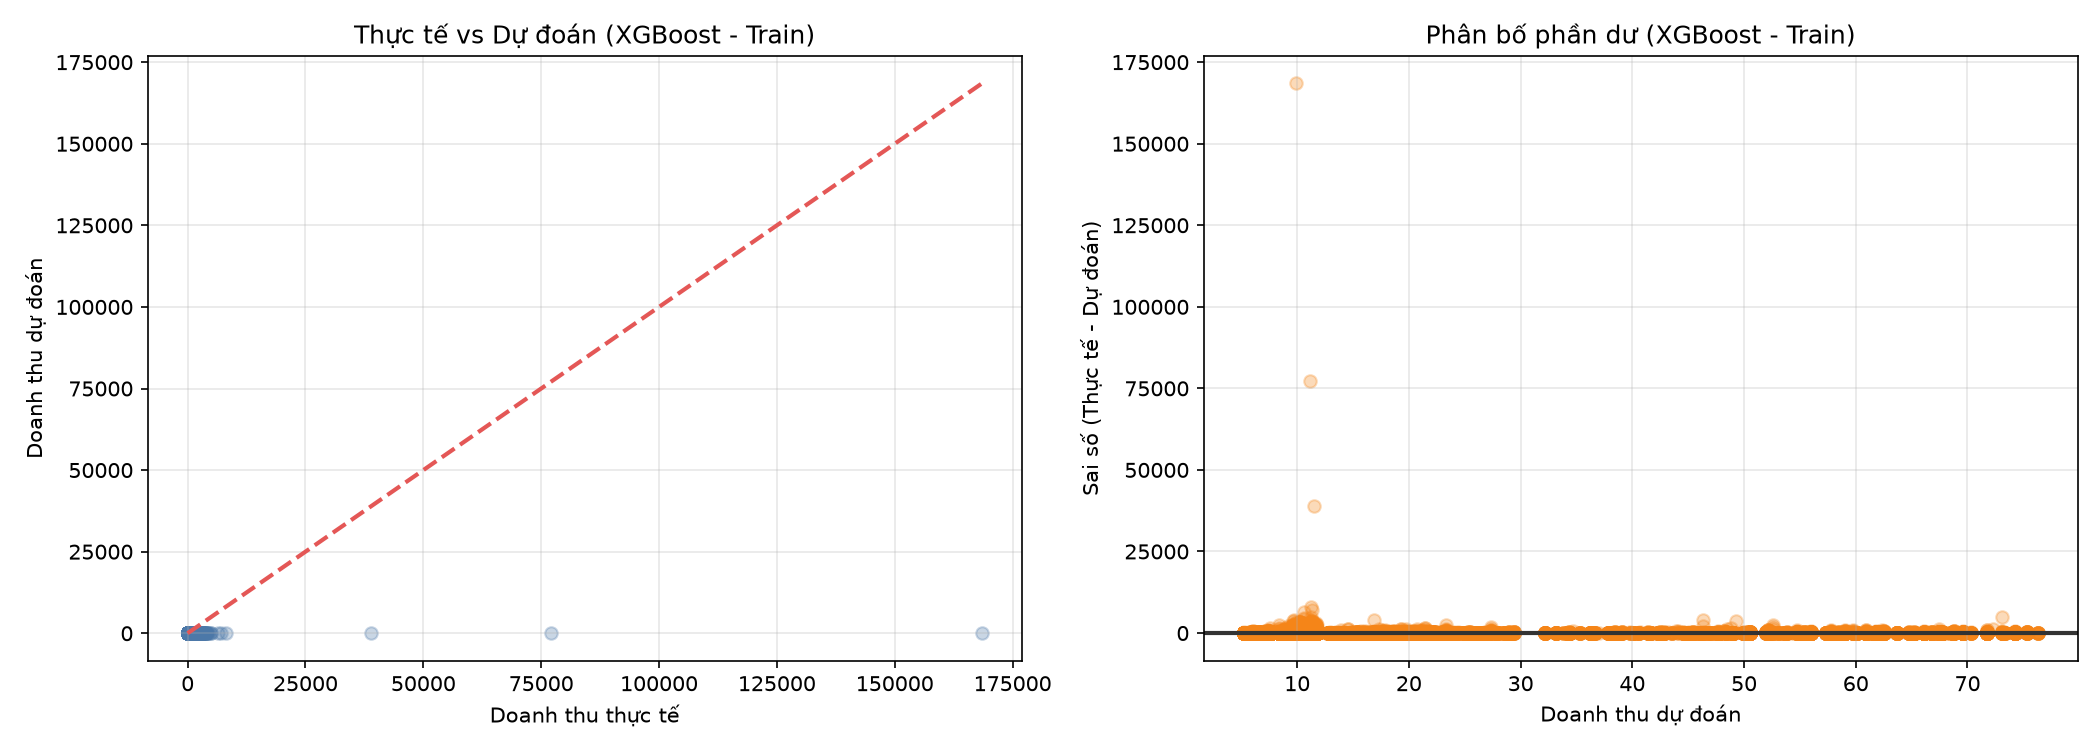

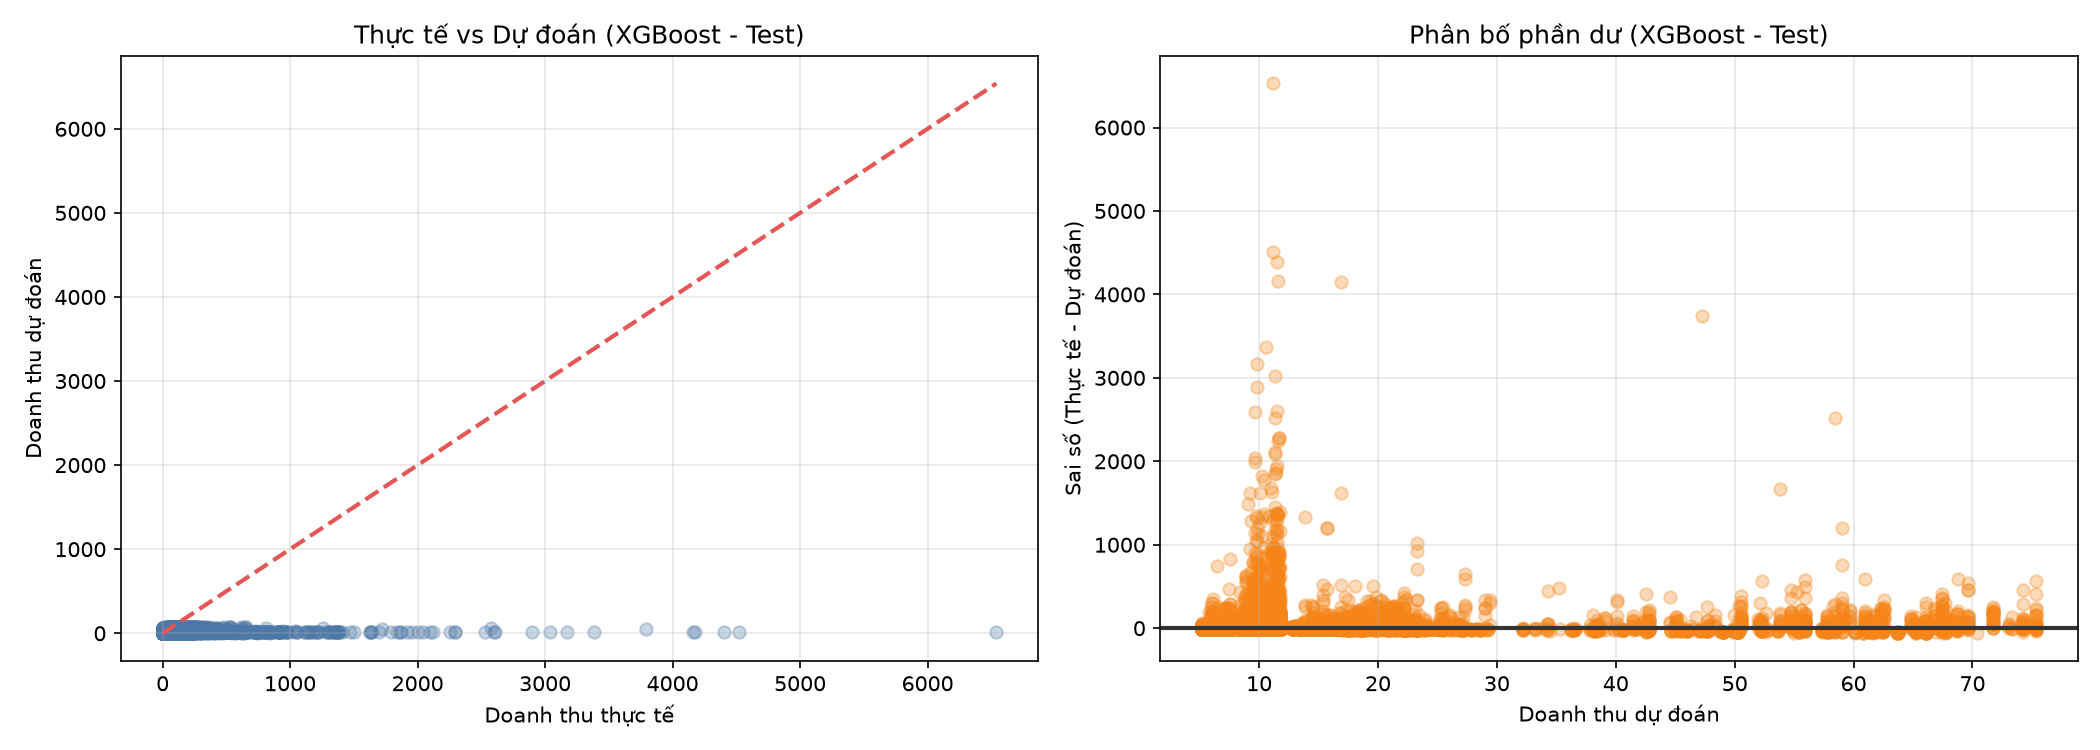

In [9]:
from IPython.display import Image, display
import os

# Đường dẫn tới thư mục chứa ảnh vừa được evaluate.py sinh ra
OUTPUT_IMAGE_DIR = os.path.join(PROJECT_ROOT, 'docs', 'images')

print("\n--- BIỂU ĐỒ CHẨN ĐOÁN: LINEAR REGRESSION ---")
display(Image(filename=os.path.join(OUTPUT_IMAGE_DIR, 'diagnostic_linear_regression_train.png')))
display(Image(filename=os.path.join(OUTPUT_IMAGE_DIR, 'diagnostic_linear_regression_test.png')))

print("\n--- BIỂU ĐỒ CHẨN ĐOÁN: DECISION TREE ---")
display(Image(filename=os.path.join(OUTPUT_IMAGE_DIR, 'diagnostic_decision_tree_train.png')))
display(Image(filename=os.path.join(OUTPUT_IMAGE_DIR, 'diagnostic_decision_tree_test.png')))

print("\n--- BIỂU ĐỒ CHẨN ĐOÁN: RANDOM FOREST ---")
display(Image(filename=os.path.join(OUTPUT_IMAGE_DIR, 'diagnostic_random_forest_train.png')))
display(Image(filename=os.path.join(OUTPUT_IMAGE_DIR, 'diagnostic_random_forest_test.png')))

print("--- BIỂU ĐỒ CHẨN ĐOÁN: XGBOOST ---")
display(Image(filename=os.path.join(OUTPUT_IMAGE_DIR, 'diagnostic_xgboost_train.png')))
display(Image(filename=os.path.join(OUTPUT_IMAGE_DIR, 'diagnostic_xgboost_test.png')))


## Step 6: Tự động hóa hoàn toàn trình (End-to-End Pipeline) với MLOps
Trong thực tế sản xuất, thay vì phải mở Notebook và chạy thủ công từng bước (Tiền xử lý -> Huấn luyện -> Đánh giá), dự án đã xây dựng một kịch bản điều phối trung tâm là `src/pipeline.py`. 

Luồng tự động này áp dụng tư duy MLOps cơ bản:
- Sử dụng `subprocess` để gọi chạy tuần tự và độc lập các module trong môi trường an toàn.
- Tự động đo lường thời gian thực thi của từng giai đoạn và tổng thời gian toàn dự án.
- Tích hợp cơ chế ngắt khẩn cấp (Fail-safe): Nếu bất kỳ module nào gặp lỗi, pipeline sẽ tự động đóng băng để bảo vệ toàn vẹn dữ liệu.

*Lưu ý: Vì chúng ta đã chạy và phân tích chi tiết từng bước ở các phần trên, đoạn code dưới đây chỉ mang tính chất minh họa cách gọi Pipeline để không làm trùng lặp tiến trình tính toán.*

**Trong thực tế vận hành (Production), người dùng chỉ cần gõ lệnh sau vào Terminal:**
- !python -m src.pipeline

**Hoặc nếu gọi từ một script Python khác, hệ thống sẽ chạy như sau:**
- import src.pipeline

- print("Đoạn code gọi hệ thống Pipeline tự động:")
- print(">>> src.pipeline.main()")

## Step 7: Triển khai và Dự đoán (Model Deployment)
Sản phẩm cuối cùng của một dự án Machine Learning là đưa mô hình vào ứng dụng thực tế. Trong bước này, chúng ta sẽ giả lập một kịch bản mà phòng Marketing chuẩn bị tung ra một sản phẩm mới và muốn dự báo doanh thu.

Hệ thống sẽ tái sử dụng lại từ điển `mappings.pkl` (chứa các thông số lịch sử đã học từ tập Train) và nạp mô hình xuất sắc nhất thông qua các hàm cốt lõi được xây dựng trong `src/predict.py`. Việc này đảm bảo tính nhất quán tuyệt đối về cấu trúc dữ liệu giữa lúc Train và lúc Predict.

In [11]:
import os
import pickle
import numpy as np
from IPython.display import display, HTML
from src.predict import prepare_features

print(" ĐANG NẠP MÔ HÌNH VÀ TỪ ĐIỂN ÁNH XẠ...")
mappings_path = os.path.join(PROJECT_ROOT, 'data', 'processed', 'mappings.pkl')
# Chọn Decision Tree vì nó đang là mô hình có R2 cao nhất trong phiên bản này 
model_path = os.path.join(PROJECT_ROOT, 'models', 'decision_tree.pkl') 

if os.path.exists(mappings_path) and os.path.exists(model_path):
    with open(mappings_path, 'rb') as f:
        mappings = pickle.load(f)
    with open(model_path, 'rb') as f:
        model = pickle.load(f)

    # Kịch bản giả định Không biết trước lượng mua
    demo_date = '2026-11-20'       
    demo_country = 'United Kingdom' 

    # 1. Gọi hàm lõi để biến đổi input thành vector đặc trưng (chỉ truyền Date và Country)
    X_input, hist_sales = prepare_features(demo_date, demo_country, mappings)
    
    # 2. Đưa vào mô hình để dự đoán và giải mã logarit (expm1)
    prediction_log = model.predict(X_input)[0]
    predicted_sales = max(0, np.expm1(prediction_log))

    # 3. In kết quả t
    print("\n" + "="*55)
    print(" 🚀 KẾT QUẢ DỰ ĐOÁN DOANH THU (KỊCH BẢN VĨ MÔ) ".center(55))
    print("="*55)
    print(f" 📅 Ngày dự kiến     : {demo_date}")
    print(f" 🌍 Quốc gia mục tiêu: {demo_country}")
    print(f" 📦 Lịch sử chi tiêu : ${hist_sales:,.2f} / đơn hàng (Trung bình)")
    print("-" * 55)
    print(f" 🎯 DOANH THU DỰ KIẾN: ${predicted_sales:,.2f} (Decision Tree)")
    print("="*55 + "\n")
    
    print(" Vector đặc trưng (X) 5 cột được đưa vào mô hình:")
    display(X_input)
else:
    print("[!] Không tìm thấy file mô hình hoặc mappings. Vui lòng chạy Pipeline trước.")

 ĐANG NẠP MÔ HÌNH VÀ TỪ ĐIỂN ÁNH XẠ...

      🚀 KẾT QUẢ DỰ ĐOÁN DOANH THU (KỊCH BẢN VĨ MÔ)     
 📅 Ngày dự kiến     : 2026-11-20
 🌍 Quốc gia mục tiêu: United Kingdom
 📦 Lịch sử chi tiêu : $20.79 / đơn hàng (Trung bình)
-------------------------------------------------------
 🎯 DOANH THU DỰ KIẾN: $8.96 (Decision Tree)

 Vector đặc trưng (X) 5 cột được đưa vào mô hình:


array([[11.        , 20.        ,  4.        ,  0.        , 20.78733553]])

## Step 8 (Mở rộng): Dự báo Chuỗi thời gian (Time Series Forecasting)
Bên cạnh việc dự đoán doanh thu dựa trên đặc trưng tĩnh, nhóm đã triển khai thêm một thuật toán **Tự hồi quy (Autoregressive - AR)** để dự báo doanh thu của 7 ngày tiếp theo trong tương lai.

Điểm đặc biệt của phương pháp này:
- Tái sử dụng lại class `LinearRegression` đã tự code từ đầu.
- Sử dụng kỹ thuật cửa sổ trượt (**Sliding Window**) với `lag = 7` để biến đổi bài toán chuỗi thời gian thành bài toán Hồi quy tuyến tính thông thường.
- Dự đoán đệ quy (Recursive Forecasting): Lấy kết quả dự đoán của ngày hôm trước đẩy vào làm dữ kiện (feature) để dự đoán cho ngày hôm sau.

 BẮT ĐẦU CHẠY DỰ BÁO CHUỖI THỜI GIAN (AUTOREGRESSIVE)...

--- BẢNG KẾT QUẢ DỰ BÁO 7 NGÀY TỚI ---


,Ngày,Dự báo Doanh thu ($)
0,2011-12-10 00:00:00,"77,815.78"
1,2011-12-11 00:00:00,"97,238.63"
2,2011-12-12 00:00:00,"83,743.28"
3,2011-12-13 00:00:00,"93,836.20"
4,2011-12-14 00:00:00,"88,803.04"
5,2011-12-15 00:00:00,"141,786.06"
6,2011-12-16 00:00:00,"77,432.23"


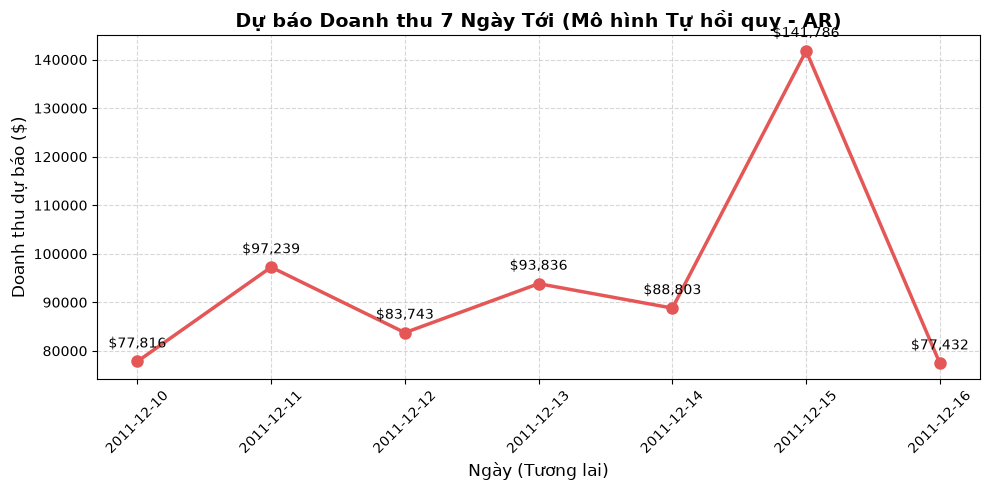

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Import hàm dự báo từ file arima.py 
from src.models.arima import forecast_next_7_days

print(" BẮT ĐẦU CHẠY DỰ BÁO CHUỖI THỜI GIAN (AUTOREGRESSIVE)...")
# Sử dụng lại df_clean từ Bước 1 (EDA) vì nó còn chứa cột InvoiceDate và Sales
forecast_df = forecast_next_7_days(df_clean)

print("\n--- BẢNG KẾT QUẢ DỰ BÁO 7 NGÀY TỚI ---")
# Hiển thị bảng dạng DataFrame
display(forecast_df.style.format({'Dự báo Doanh thu ($)': "{:,.2f}"}))

plt.figure(figsize=(10, 5))
plt.plot(forecast_df['Ngày'], forecast_df['Dự báo Doanh thu ($)'], 
         marker='o', color='#e45756', linewidth=2.5, markersize=8)

# Vòng lặp để in trực tiếp con số lên từng điểm của biểu đồ
for i, txt in enumerate(forecast_df['Dự báo Doanh thu ($)']):
    plt.annotate(f"${txt:,.0f}", 
                 (forecast_df['Ngày'].iloc[i], forecast_df['Dự báo Doanh thu ($)'].iloc[i]),
                 textcoords="offset points", xytext=(0,10), ha='center', fontsize=10)

plt.title('Dự báo Doanh thu 7 Ngày Tới (Mô hình Tự hồi quy - AR)', fontsize=14, fontweight='bold')
plt.xlabel('Ngày (Tương lai)', fontsize=12)
plt.ylabel('Doanh thu dự báo ($)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Step 9 (Mở rộng): Hệ thống Gợi ý Sản phẩm (Recommendation System)
Yêu cầu bổ sung của đề tài đặt ra bài toán: "Làm thế nào để gợi ý sản phẩm phù hợp cho khách hàng?". Để giải quyết, nhóm đã xây dựng thuật toán **Lọc cộng tác dựa trên người dùng (User-Based Collaborative Filtering)** từ con số 0 (không dùng thư viện).

Thuật toán hoạt động theo các bước:
1. Xây dựng ma trận Người dùng - Sản phẩm (User-Item Matrix).
2. Tính toán độ tương đồng Cosine (Cosine Similarity) bằng phép nhân ma trận giữa khách hàng mục tiêu và toàn bộ khách hàng khác.
3. Tìm ra tập hợp (Top 10) những "người hàng xóm" có hành vi mua sắm giống nhất.
4. Gợi ý những sản phẩm mà "người hàng xóm" đã mua nhưng khách hàng mục tiêu chưa từng mua.

In [13]:
# Import hàm gợi ý từ file src/models/recommender.py
from src.models.recommender import get_recommendations

print(" KHỞI ĐỘNG HỆ THỐNG GỢI Ý SẢN PHẨM (COLLABORATIVE FILTERING)...")

# 1. Chọn ngẫu nhiên một khách hàng từ tập dữ liệu sạch (df_clean)
sample_customer_id = int(df_clean['CustomerID'].dropna().iloc[0])

print(f"\n[*] Khách hàng mục tiêu đang phân tích: {sample_customer_id}")

# 2. Gọi hàm tính toán để lấy Top 5 sản phẩm gợi ý
recommended_products = get_recommendations(
    customer_id=sample_customer_id, 
    df=df_clean, 
    top_n=5
)

# 3. Trực quan hóa kết quả đầu ra
print("\n" + "="*65)
print(f" 🎯 TOP 5 SẢN PHẨM GỢI Ý CHO KHÁCH HÀNG {sample_customer_id} ".center(65))
print("="*65)

if recommended_products:
    for i, product in enumerate(recommended_products, 1):
        print(f"  {i}. {product}")
else:
    print(" [!] Khách hàng chưa đủ dữ liệu hoặc đã mua hầu hết các món phổ biến.")
print("="*65 + "\n")

 KHỞI ĐỘNG HỆ THỐNG GỢI Ý SẢN PHẨM (COLLABORATIVE FILTERING)...

[*] Khách hàng mục tiêu đang phân tích: 17850

           🎯 TOP 5 SẢN PHẨM GỢI Ý CHO KHÁCH HÀNG 17850           
  1. WOOD BLACK BOARD ANT WHITE FINISH
  2. SET/20 STRAWBERRY PAPER NAPKINS 
  3. CREAM SWEETHEART MINI CHEST
  4. HEART OF WICKER SMALL
  5. ORGANISER WOOD ANTIQUE WHITE 



## Step 10 — Mô hình Cuối cùng & Hệ Sinh Thái AI 
Khác với các phương pháp báo cáo truyền thống chỉ dừng lại ở Notebook, nhóm đã đưa các file trọng số `.pkl` vào triển khai thực tế thông qua Giao diện Web **Streamlit (`app.py`)**. 

Hệ sinh thái tích hợp 3 trụ cột AI:
1. Dự đoán Doanh thu đơn hàng (Regression Models).
2. Dự báo Chuỗi thời gian 7 ngày tới (Autoregressive Linear Model).
3. Gợi ý Sản phẩm (User-Based Collaborative Filtering bằng Cosine Similarity).

## Step 11 — Tổng kết & Hướng phát triển (Summary & Next Steps)
**Kết luận:**
- Dự án đã xây dựng **thành công một Hệ sinh thái AI Bán lẻ toàn diện**, tích hợp 3 phân hệ cốt lõi: Dự báo doanh thu (Regression), Dự báo chuỗi thời gian (Autoregression) và Hệ thống gợi ý (Collaborative Filtering). Điểm sáng giá nhất của dự án là việc hiện thực hóa 100% các thuật toán học máy phức tạp (Linear Regression, Decision Tree, Random Forest, XGBoost) hoàn toàn bằng toán học từ con số 0 (from scratch). 

- Chia tách tập Train/Test trước khi thực hiện các bước tính toán tổng hợp hoặc mã hóa đã giúp ngăn chặn triệt để hiện tượng rò rỉ dữ liệu (Data Leakage). Bên cạnh đó, hệ thống đã được đóng gói thành các luồng Pipeline tự động hóa tích hợp cơ chế ghi log (experiment tracking) và cơ chế ngắt khẩn cấp (fail-safe) để bảo vệ dữ liệu.

- Mặc dù kiến trúc toán học và quy trình xử lý dữ liệu hoạt động hoàn hảo, hiệu năng dự báo thực tế của mô hình hồi quy còn khiêm tốn, với thuật toán tốt nhất là Decision Tree chỉ đạt $R^2 = 0.0119$ trên tập Test. Nguyên nhân gốc rễ không nằm ở thuật toán, mà đến từ quyết định chiến lược ở bước Feature Engineering: dự án đã chủ động loại bỏ hai biến quan trọng nhất là Số lượng (Quantity) và Đơn giá (UnitPrice) nhằm ép mô hình dự đoán dựa trên bối cảnh thời gian và sức mua trung bình của quốc gia. Việc thiếu hụt các đặc trưng mang tính "tín hiệu cao" (high-signal features) khiến mô hình không đủ cơ sở dữ liệu để giải thích sự biến thiên phức tạp của từng đơn hàng lẻ.

**Hướng phát triển tương lai:**
1. Tái thiết kế Đặc trưng Dữ liệu (Feature Engineering 2.0)

Để cải thiện đột phá chỉ số $R^2$ mà không vi phạm nguyên tắc chống rò rỉ dữ liệu, hệ thống cần được bổ sung các đặc trưng vĩ mô và vi mô sâu hơn:
 - **Chỉ số RFM (Recency, Frequency, Monetary):** Tính toán độ ngẫu nhiên mua hàng, tần suất và giá trị chi tiêu của từng khách hàng (CustomerID) dựa trên lịch sử tập Train, sau đó map sang tập Test. Điều này cung cấp bối cảnh vi mô chính xác hơn nhiều so với việc chỉ dùng sức mua trung bình của Quốc gia.
 - **Đặc trưng độ trễ (Lagged Features):** Bổ sung các biến như doanh thu của sản phẩm/khách hàng đó trong 7 ngày hoặc 30 ngày trước.
 - Phân cụm khách hàng (Clustering): Sử dụng K-Means để phân nhóm khách hàng trên tập Train, biến nhãn cụm (Cluster ID) thành một đặc trưng phân loại (Categorical Feature) cho mô hình dự báo.

2. Điều chỉnh Mục tiêu Bài toán (Business Problem Reframing)

Dự đoán doanh thu của một "đơn hàng lẻ" tại một thời điểm ngẫu nhiên mà không có dữ liệu về lượng hàng (Quantity) là một bài toán gần như bất khả thi do tính nhiễu (noise) cao. Dự án nên chuyển hướng mục tiêu sang các bài toán mang lại giá trị vận hành thực tiễn hơn:

- **Dự báo Giá trị Vòng đời Khách hàng (Customer Lifetime Value - CLV):** Dự đoán tổng mức chi tiêu của một CustomerID cụ thể trong 30 ngày tới.

- **Dự báo Nhu cầu Tồn kho (Inventory Demand Forecasting):** Chuyển từ dự đoán doanh thu sang dự đoán tổng số lượng (Total Quantity) cần chuẩn bị cho từng mã sản phẩm (StockCode) trong tuần tới, phục vụ trực tiếp cho phòng Chuỗi cung ứng (Supply Chain).

3. Tối ưu Hệ thống Gợi ý (Recommender System Optimization)

Để khắc phục giới hạn bộ nhớ của thuật toán User-Based CF khi hệ thống mở rộng, cần tối ưu theo hai hướng:

- **Chuyển sang Item-Based CF:** Tính toán độ tương đồng giữa các sản phẩm giúp tiết kiệm tài nguyên và đem lại độ ổn định cao hơn so với đo lường hành vi người dùng.

- **Áp dụng Phân rã Ma trận (SVD/ALS):** Kết hợp kỹ thuật ma trận thưa (Sparse Matrix) nhằm giải quyết triệt để tình trạng dữ liệu phân tán và tối ưu hóa dung lượng RAM.

4. Nâng cấp Kiến trúc Triển khai (Advanced MLOps & Deployment)

Để hệ sinh thái ứng dụng Streamlit hiện tại đạt chuẩn Production:   
- **Containerization:** Đóng gói toàn bộ mô hình và giao diện Web bằng Docker để đảm bảo tính đồng nhất trên mọi môi trường chạy.
- **dern Tracking:** Nâng cấp từ việc ghi log vào file CSV sang sử dụng các nền tảng tracking chuyên dụng như MLflow hoặc Weights & Biases để trực quan hóa lịch sử tinh chỉnh siêu tham số trực tiếp trên web. 